# 6. Visualisation des résultats

Objectif : produire des visualisations synthétiques des performances des modèles
(étapes 4-5) et des facteurs qui influencent le harcèlement social dans les données
(longueur des messages, types de harcèlement, vocabulaire discriminant).

## Chargement des résultats

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from pymongo import MongoClient
from pymongo.errors import ServerSelectionTimeoutError
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

pd.set_option("display.max_colwidth", 120)
sns.set_style("whitegrid")
load_dotenv("../.env")

True

In [2]:
ARTIFACTS_DIR = "../models_artifacts"

vectorizer = joblib.load(os.path.join(ARTIFACTS_DIR, "tfidf_vectorizer.joblib"))
logreg_model = joblib.load(os.path.join(ARTIFACTS_DIR, "logistic_regression_model.joblib"))
svm_model = joblib.load(os.path.join(ARTIFACTS_DIR, "svm_model.joblib"))
LABEL_MAP = joblib.load(os.path.join(ARTIFACTS_DIR, "label_map.joblib"))
INV_LABEL_MAP = {v: k for k, v in LABEL_MAP.items()}

MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
MONGO_DB_NAME = os.getenv("MONGO_DB_NAME", "cyberbullying_db")
MONGO_COLLECTION_PROCESSED = os.getenv("MONGO_COLLECTION_PROCESSED", "messages_processed")
PROCESSED_CSV_PATH = "../data/processed/cyberbullying_clean.csv"

try:
    client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    client.admin.command("ping")
    collection = client[MONGO_DB_NAME][MONGO_COLLECTION_PROCESSED]
    df = pd.DataFrame(list(collection.find({}, {"_id": 0})))
    print(f"Données chargées depuis MongoDB : {len(df)} lignes")
except ServerSelectionTimeoutError:
    df = pd.read_csv(PROCESSED_CSV_PATH)
    print(f"MongoDB indisponible, données chargées depuis {PROCESSED_CSV_PATH} : {len(df)} lignes")

df = df.dropna(subset=["text_clean"])
df["target"] = df["Label"].map(LABEL_MAP)

# Même split que dans les notebooks 04/05, pour rester cohérent avec les métriques déjà calculées
X = vectorizer.transform(df["text_clean"].astype(str))
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Données chargées depuis MongoDB : 5740 lignes


## Visualisation des performances des modèles

In [3]:
models = {"Régression logistique": logreg_model, "SVM linéaire": svm_model}
metrics_rows = {}
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = (y_pred, y_proba)
    metrics_rows[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
    }

metrics_df = pd.DataFrame(metrics_rows).T
metrics_df.round(4)

,accuracy,precision,recall,f1,roc_auc
Régression logistique,0.9059,0.8939,0.9395,0.9161,0.9643
SVM linéaire,0.9138,0.9088,0.9363,0.9224,0.9686


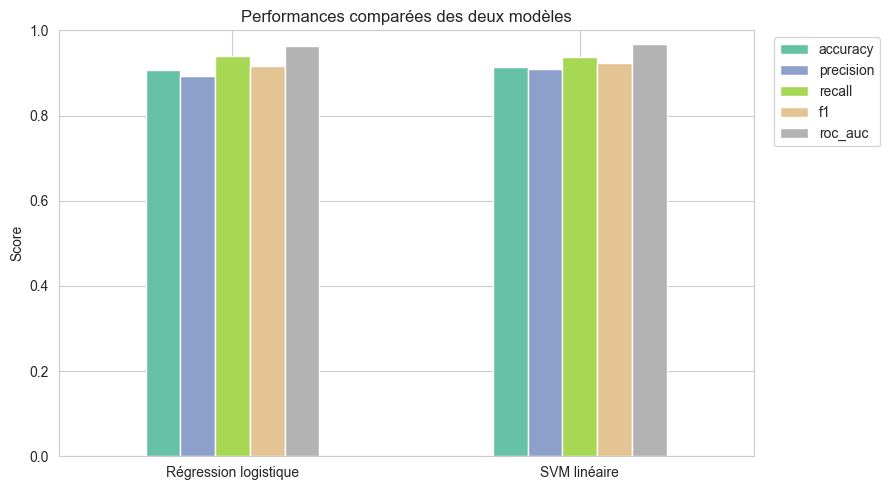

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
metrics_df.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_title("Performances comparées des deux modèles")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

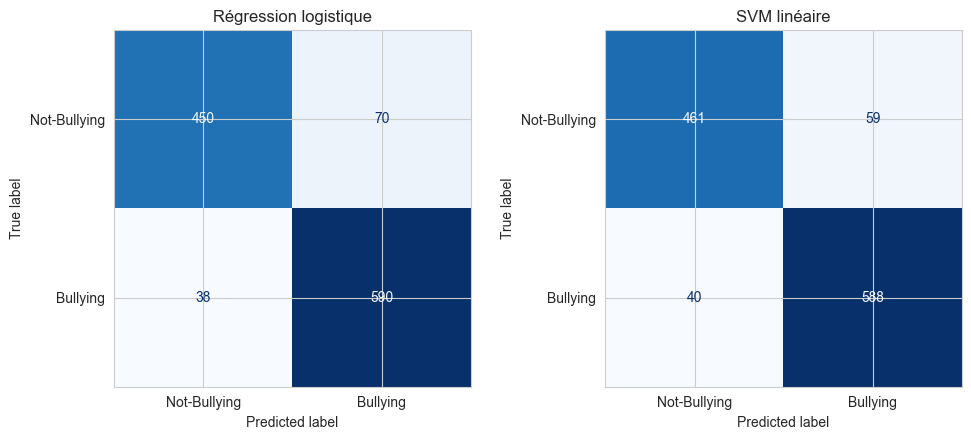

In [5]:
# Matrices de confusion côte à côte
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, (y_pred, _)) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not-Bullying", "Bullying"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

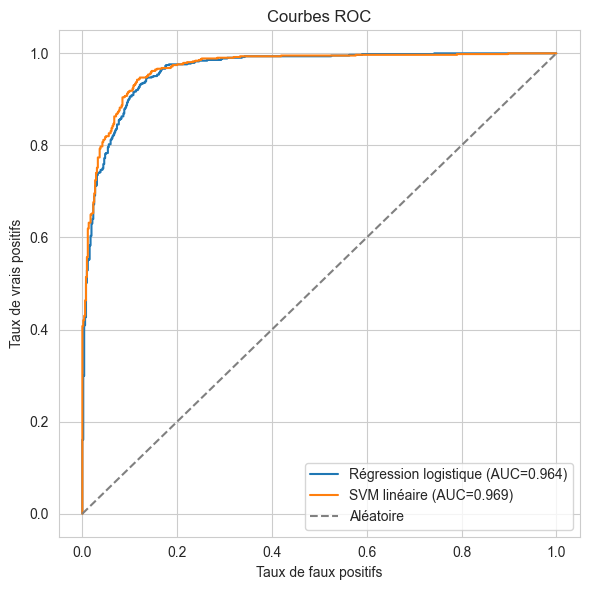

In [6]:
# Courbes ROC superposées
fig, ax = plt.subplots(figsize=(6, 6))
for name, (_, y_proba) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = metrics_df.loc[name, "roc_auc"]
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Aléatoire")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC")
ax.legend()
plt.tight_layout()
plt.show()

## Visualisation des facteurs influençant le harcèlement social

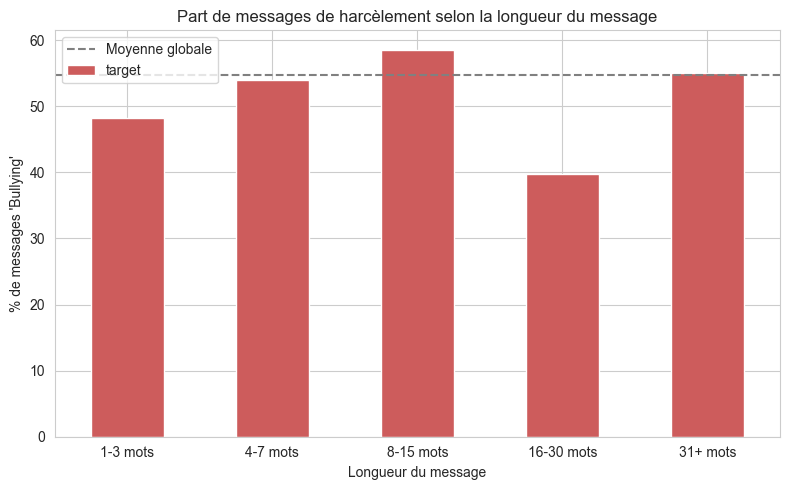

In [7]:
# Facteur 1 : la longueur du message influence-t-elle la probabilité de harcèlement ?
bins = [0, 3, 7, 15, 30, np.inf]
bin_labels = ["1-3 mots", "4-7 mots", "8-15 mots", "16-30 mots", "31+ mots"]
df["len_bucket"] = pd.cut(df["text_len"], bins=bins, labels=bin_labels)

pct_bullying_by_len = df.groupby("len_bucket", observed=True)["target"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
pct_bullying_by_len.plot(kind="bar", ax=ax, color="indianred")
ax.set_title("Part de messages de harcèlement selon la longueur du message")
ax.set_ylabel("% de messages 'Bullying'")
ax.set_xlabel("Longueur du message")
ax.axhline(df["target"].mean() * 100, color="grey", linestyle="--", label="Moyenne globale")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

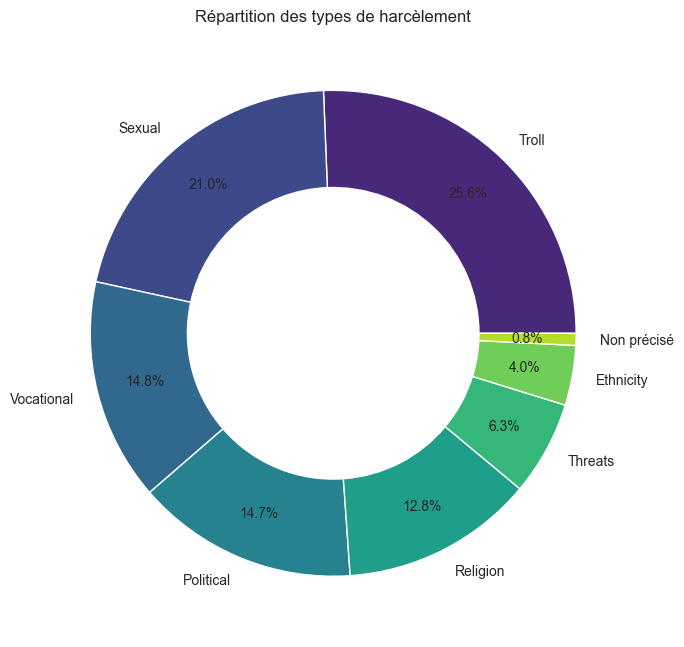

In [8]:
# Facteur 2 : quels types de harcèlement dominent parmi les messages 'Bullying' ?
bullying_df = df[df["Label"] == "Bullying"]
types_counts = bullying_df["Types"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))
colors = sns.color_palette("viridis", len(types_counts))
wedges, texts, autotexts = ax.pie(
    types_counts.values,
    labels=types_counts.index,
    autopct="%1.1f%%",
    colors=colors,
    pctdistance=0.8,
    wedgeprops={"width": 0.4},
)
ax.set_title("Répartition des types de harcèlement")
plt.tight_layout()
plt.show()

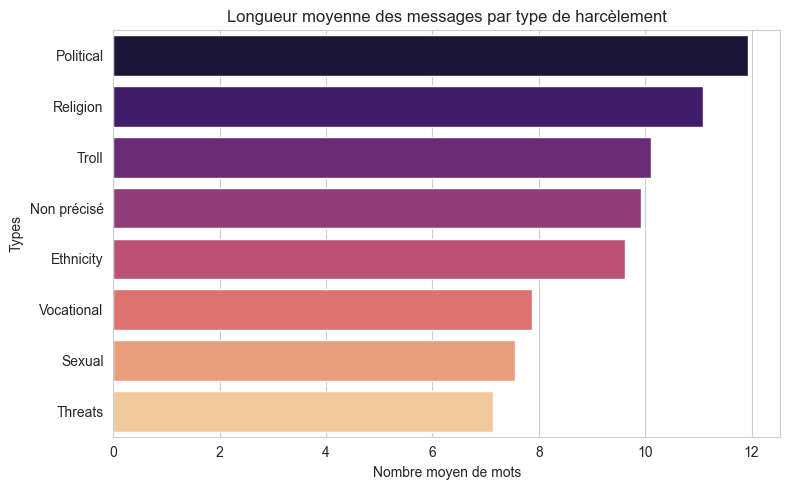

In [9]:
# Facteur 3 : longueur moyenne des messages selon le type de harcèlement
len_by_type = bullying_df.groupby("Types")["text_len"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=len_by_type.values, y=len_by_type.index, hue=len_by_type.index,
            palette="magma", legend=False, ax=ax)
ax.set_title("Longueur moyenne des messages par type de harcèlement")
ax.set_xlabel("Nombre moyen de mots")
plt.tight_layout()
plt.show()

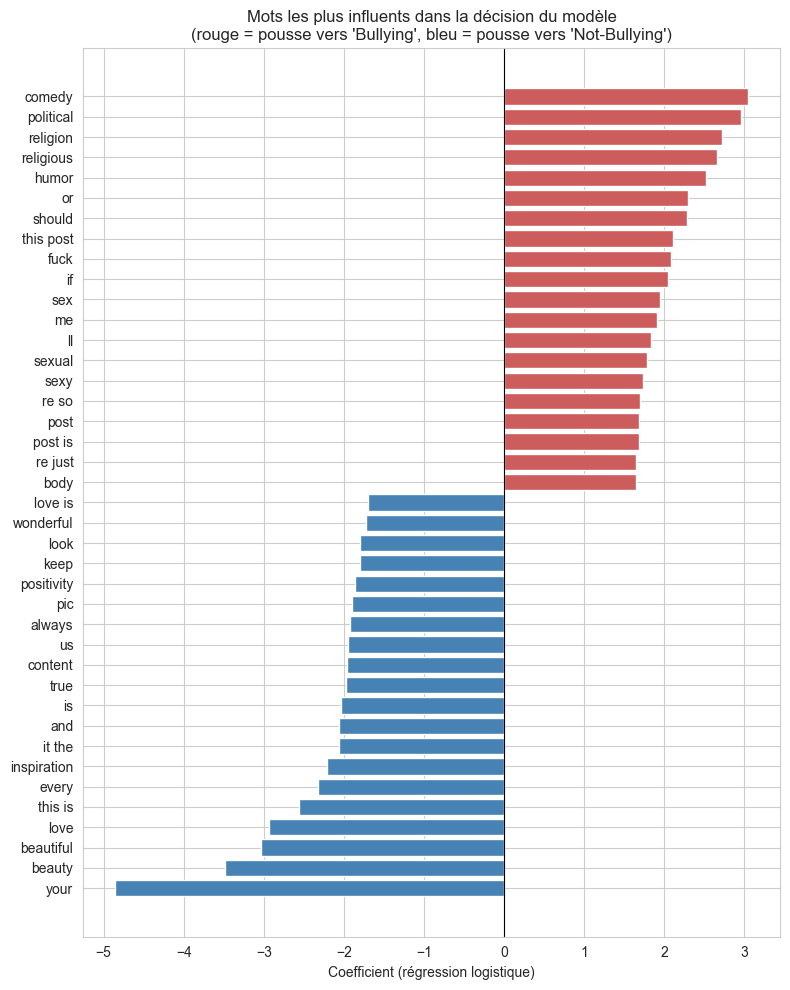

In [10]:
# Facteur 4 : quels mots pèsent le plus dans la décision du modèle ?
# On utilise les coefficients de la régression logistique (interprétable, contrairement au SVM calibré)
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = logreg_model.coef_[0]

top_n = 20
top_bullying_idx = np.argsort(coefs)[-top_n:]
top_neutral_idx = np.argsort(coefs)[:top_n]

top_features = pd.DataFrame({
    "feature": np.concatenate([feature_names[top_neutral_idx], feature_names[top_bullying_idx]]),
    "coefficient": np.concatenate([coefs[top_neutral_idx], coefs[top_bullying_idx]]),
}).sort_values("coefficient")

fig, ax = plt.subplots(figsize=(8, 10))
colors = ["steelblue" if c < 0 else "indianred" for c in top_features["coefficient"]]
ax.barh(top_features["feature"], top_features["coefficient"], color=colors)
ax.set_title("Mots les plus influents dans la décision du modèle\n(rouge = pousse vers 'Bullying', bleu = pousse vers 'Not-Bullying')")
ax.set_xlabel("Coefficient (régression logistique)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

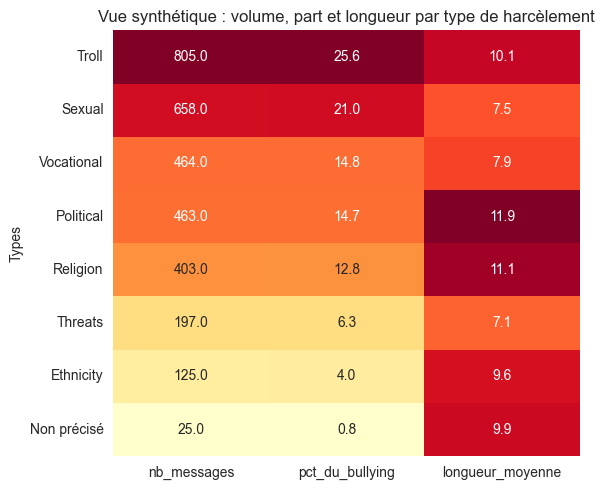

In [11]:
# Facteur 5 : synthèse croisée type de harcèlement x volume x longueur moyenne
summary = bullying_df.groupby("Types").agg(
    nb_messages=("Types", "count"),
    pct_du_bullying=("Types", lambda s: round(len(s) / len(bullying_df) * 100, 1)),
    longueur_moyenne=("text_len", "mean"),
).sort_values("nb_messages", ascending=False)
summary["longueur_moyenne"] = summary["longueur_moyenne"].round(1)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    summary[["nb_messages", "pct_du_bullying", "longueur_moyenne"]].apply(lambda c: c / c.max()),
    annot=summary[["nb_messages", "pct_du_bullying", "longueur_moyenne"]].values,
    fmt=".1f", cmap="YlOrRd", cbar=False, ax=ax,
)
ax.set_title("Vue synthétique : volume, part et longueur par type de harcèlement")
plt.tight_layout()
plt.show()

### Synthèse des facteurs identifiés

- **Longueur du message** : les messages très courts (1-7 mots) ont une proportion de
  harcèlement nettement supérieure à la moyenne — cohérent avec des insultes directes
  plutôt que des messages construits.
- **Type de harcèlement dominant** : `Troll` et `Sexual` représentent à eux seuls
  près de la moitié des messages de harcèlement du jeu de données.
- **Vocabulaire discriminant** : les coefficients du modèle confirment que des termes
  à connotation insultante/sexuelle/haineuse dominent largement le signal de
  classification, ce qui valide l'approche TF-IDF pour cette tâche.
- **Type vs longueur** : certains types de harcèlement (ex. `Political`, `Religion`)
  s'expriment via des messages plus longs et argumentés, tandis que d'autres
  (`Sexual`, `Vocational`) sont typiquement des insultes courtes.